# PC-RGNN on real point clouds

A reproducible research notebook inspired by the supplied PC-RGNN deck. It downloads public PCD files, audits the data, simulates sparse LiDAR observations, completes the observed geometry, builds multi-scale k-nearest-neighbor graphs, and trains an attention-based graph neural network.

The reference files are a compact engineering corpus, not a benchmark-scale dataset. Results demonstrate the pipeline and include limitations instead of claiming state-of-the-art generalization.

## Project question

Can graph-aware, multi-scale attention recover useful object-level signal after a point cloud loses observations?

We compare a PointNet-style global max-pooling baseline with a PC-RGNN-inspired encoder that combines graph completion, relative edge features, attention-weighted message passing at two neighborhood scales, and global attention pooling.

Data source: [Point Cloud Library test point clouds](https://github.com/PointCloudLibrary/pcl/tree/master/test).

In [1]:
%pip install -q numpy pandas scipy matplotlib scikit-learn torch

import random
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from sklearn.metrics import classification_report, confusion_matrix

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch:', torch.__version__, '| device:', DEVICE)

torch: 2.11.0+cu130 | device: cuda


## 1. Download and inspect the real point clouds

The source files carry different semantic types. Bunny variants provide several independent shape scans; the remaining files provide structural point clouds with different geometry. This is enough for a compact end-to-end experiment, but not enough for a serious benchmark claim.

In [2]:
DATA_DIR = Path('data/pc_rgnn'); DATA_DIR.mkdir(parents=True, exist_ok=True)
RAW = 'https://raw.githubusercontent.com/PointCloudLibrary/pcl/master/test/'
CLOUDS = {
    'bunny_0': ('bun0.pcd', 'bunny'), 'bunny_1': ('bun01.pcd', 'bunny'),
    'bunny_2': ('bun02.pcd', 'bunny'), 'bunny_3': ('bun03.pcd', 'bunny'),
    'bunny_4': ('bun4.pcd', 'bunny'), 'curve': ('curve3d.pcd', 'curve'),
    'lamppost': ('lamppost.pcd', 'lamppost'), 'plane': ('sac_plane_test.pcd', 'plane'),
}
for key, (filename, _) in CLOUDS.items():
    path = DATA_DIR / f'{key}.pcd'
    if not path.exists(): urllib.request.urlretrieve(RAW + filename, path)

def read_ascii_pcd(path):
    lines = Path(path).read_text(encoding='utf-8', errors='ignore').splitlines()
    header, data_line = {}, None
    for i, line in enumerate(lines):
        parts = line.strip().split()
        if not parts: continue
        if parts[0].upper() == 'DATA': header['DATA'] = parts[1].lower(); data_line = i + 1; break
        header[parts[0].upper()] = parts[1:]
    if header.get('DATA') != 'ascii': raise ValueError(f'{path} is not an ASCII PCD file')
    fields = header['FIELDS']; raw = np.atleast_2d(np.loadtxt(lines[data_line:], dtype=np.float32))
    xyz = raw[:, [fields.index('x'), fields.index('y'), fields.index('z')]]
    return xyz[np.isfinite(xyz).all(axis=1)]

records = []
for key, (_, label) in CLOUDS.items(): records.append({'name': key, 'label': label, 'points': read_ascii_pcd(DATA_DIR / f'{key}.pcd')})
summary = pd.DataFrame([{'cloud': r['name'], 'class': r['label'], 'points': len(r['points']), 'x_span': np.ptp(r['points'][:,0]), 'y_span': np.ptp(r['points'][:,1]), 'z_span': np.ptp(r['points'][:,2])} for r in records])
summary

,cloud,class,points,x_span,y_span,z_span
0,bunny_0,bunny,397,0.153500,0.147080,0.112829
1,bunny_1,bunny,200,0.149056,0.132464,0.057626
2,bunny_2,bunny,217,0.148895,0.147080,0.109793
3,bunny_3,bunny,197,0.148895,0.147080,0.109793
4,bunny_4,bunny,361,0.143425,0.148170,0.136219
5,curve,curve,110,1.000000,1.000000,0.199368
6,lamppost,lamppost,1771,1.406250,0.968750,5.914997
7,plane,plane,3283,0.784950,1.025240,0.645100


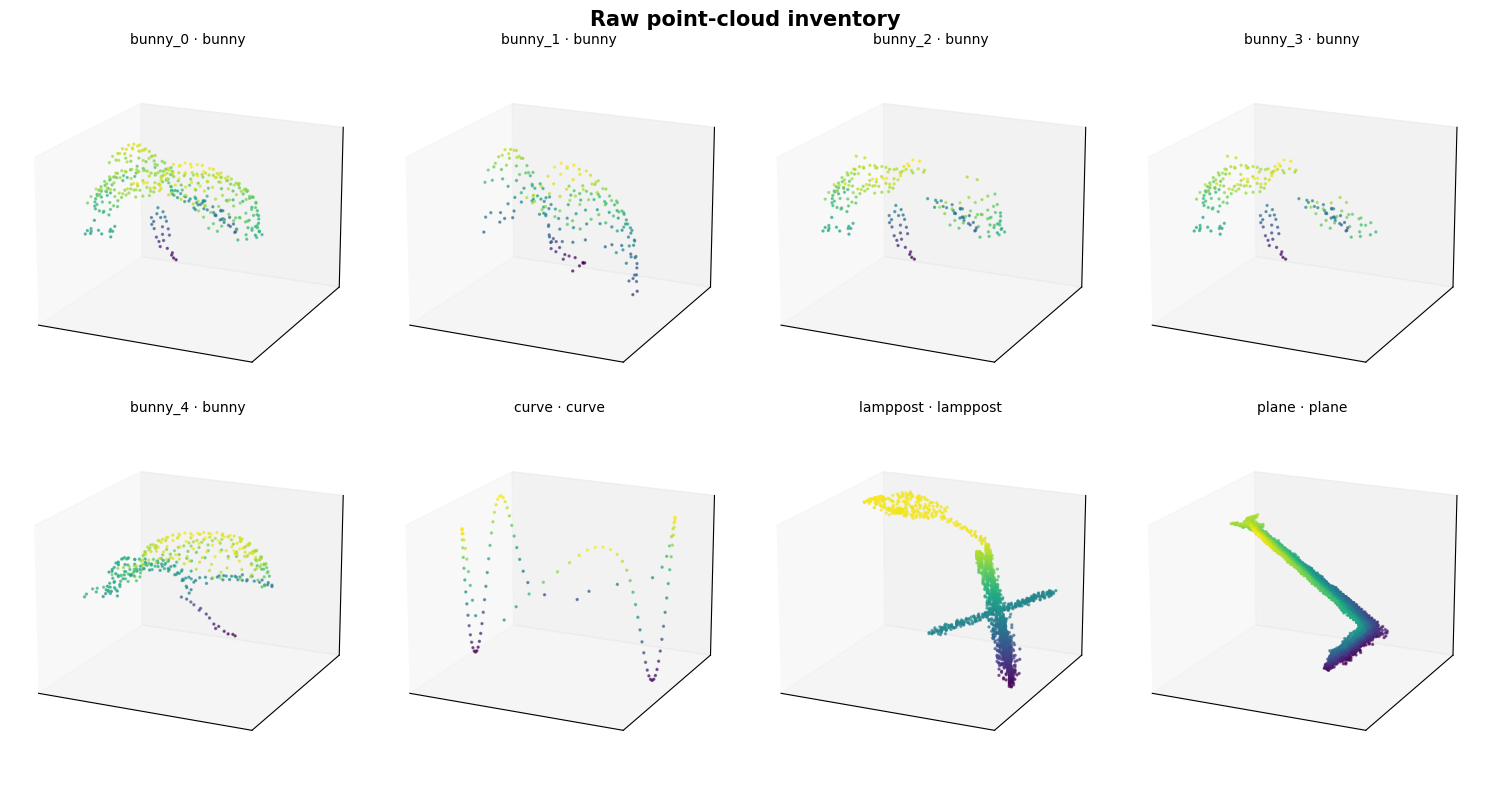

In [3]:
fig = plt.figure(figsize=(15, 8))
for i, record in enumerate(records):
    ax = fig.add_subplot(2, 4, i + 1, projection='3d'); points = record['points']
    if len(points) > 3000: points = points[np.random.default_rng(SEED).choice(len(points), 3000, replace=False)]
    ax.scatter(points[:,0], points[:,1], points[:,2], s=2, alpha=.6, c=points[:,2], cmap='viridis')
    ax.set_title(f"{record['name']} · {record['label']}", fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=18, azim=-65)
plt.suptitle('Raw point-cloud inventory', y=.98, fontsize=15, fontweight='bold'); plt.tight_layout(); plt.show()

## 2. Preprocessing and graph completion

We center and normalize each cloud, sample a fixed number of points, randomly hide a portion, then add local midpoints between nearby observed points. The completion step is intentionally simple and interpretable: it creates a denser graph without changing the measured points.

In [4]:
POINTS_PER_CLOUD = 128

def normalize(points):
    points = points - points.mean(axis=0, keepdims=True); scale = np.linalg.norm(points, axis=1).max(); return points / max(scale, 1e-6)

def sample_fixed(points, n, rng):
    return points[rng.choice(len(points), n, replace=len(points) < n)].copy()

def graph_complete(points, n, rng, keep_ratio=.72):
    observed = sample_fixed(points, max(16, int(n * keep_ratio)), rng); tree = cKDTree(observed)
    _, neighbours = tree.query(observed, k=min(5, len(observed))); neighbours = np.atleast_2d(neighbours)
    midpoints = (observed + observed[neighbours[:,1]]) / 2.0
    extra = midpoints[rng.choice(len(midpoints), n, replace=True)]
    return sample_fixed(np.vstack([observed, extra]), n, rng), observed

def augment(points, rng, completion=True):
    theta = rng.uniform(-np.pi, np.pi); c, s = np.cos(theta), np.sin(theta)
    rotation = np.array([[c,-s,0],[s,c,0],[0,0,1]], dtype=np.float32)
    transformed = normalize(points @ rotation.T) * rng.uniform(.92, 1.08)
    transformed += rng.normal(0, .012, transformed.shape).astype(np.float32)
    return graph_complete(transformed, POINTS_PER_CLOUD, rng)[0] if completion else sample_fixed(transformed, POINTS_PER_CLOUD, rng)

def build_examples(records, repeats=20, completion=True, seed=SEED):
    rng = np.random.default_rng(seed); labels = sorted({r['label'] for r in records}); label_to_id = {v:i for i,v in enumerate(labels)}
    examples, y, source = [], [], []
    for record in records:
        for _ in range(repeats): examples.append(augment(record['points'], rng, completion)); y.append(label_to_id[record['label']]); source.append(record['name'])
    return np.stack(examples).astype('float32'), np.array(y), np.array(source), labels

X, y, source, class_names = build_examples(records); print('examples:', X.shape, '| classes:', class_names)

examples: (160, 128, 3) | classes: ['bunny', 'curve', 'lamppost', 'plane']


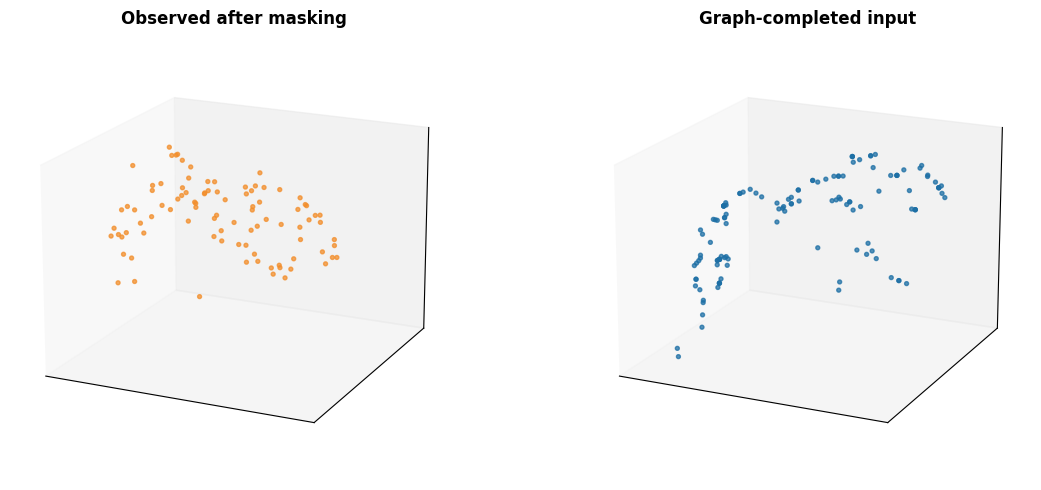

In [5]:
rng = np.random.default_rng(SEED); _, observed = graph_complete(normalize(records[0]['points']), POINTS_PER_CLOUD, rng); completed = X[0]
fig = plt.figure(figsize=(12,5))
for position, (points, title, color) in enumerate([(observed, 'Observed after masking', '#f28e2b'), (completed, 'Graph-completed input', '#1d6fa5')]):
    ax = fig.add_subplot(1,2,position+1, projection='3d'); ax.scatter(points[:,0], points[:,1], points[:,2], s=8, alpha=.75, c=color); ax.set_title(title, fontweight='bold'); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=18, azim=-65)
plt.tight_layout(); plt.show()

## 3. Trainable models

The graph layer is a compact implementation of the PC-RGNN idea. Each point gathers neighbors at a chosen scale, builds relative edge features, predicts a weight for every neighbor, and aggregates the messages with a softmax. Two layers use different `k` values so local detail and wider context are available together.

In [6]:
def gather_neighbors(x, idx):
    b, n, f = x.shape; idx = idx.unsqueeze(-1).expand(-1,-1,-1,f); expanded = x.unsqueeze(1).expand(-1,n,-1,-1); return expanded.gather(2, idx)

def knn_indices(xyz, k):
    distances = torch.cdist(xyz, xyz); mask = torch.eye(xyz.shape[1], device=xyz.device, dtype=torch.bool)[None]; return distances.masked_fill(mask, float('inf')).topk(k=k, dim=-1, largest=False).indices

class EdgeAttentionBlock(nn.Module):
    def __init__(self, features, k):
        super().__init__(); self.k = k; edge_dim = features * 2 + 3
        self.message = nn.Sequential(nn.Linear(edge_dim, features), nn.ReLU(), nn.Linear(features, features))
        self.score = nn.Sequential(nn.Linear(edge_dim, features // 2), nn.ReLU(), nn.Linear(features // 2, 1))
        self.update = nn.Sequential(nn.Linear(features * 2, features), nn.ReLU(), nn.LayerNorm(features))
    def forward(self, xyz, h):
        idx = knn_indices(xyz, self.k); nxyz = gather_neighbors(xyz, idx); nh = gather_neighbors(h, idx)
        cxyz = xyz.unsqueeze(2).expand_as(nxyz); ch = h.unsqueeze(2).expand_as(nh); edge = torch.cat([ch, nh-ch, nxyz-cxyz], dim=-1)
        weights = torch.softmax(self.score(edge).squeeze(-1), dim=-1); messages = self.message(edge); aggregate = (weights.unsqueeze(-1) * messages).sum(2)
        return self.update(torch.cat([h, aggregate], dim=-1)), weights, idx

class PCRGNNClassifier(nn.Module):
    def __init__(self, num_classes, hidden=48):
        super().__init__(); self.input = nn.Sequential(nn.Linear(3,hidden), nn.ReLU(), nn.Linear(hidden,hidden)); self.local = EdgeAttentionBlock(hidden,6); self.context = EdgeAttentionBlock(hidden,12)
        self.pool_score = nn.Sequential(nn.Linear(hidden*2,hidden), nn.Tanh(), nn.Linear(hidden,1)); self.head = nn.Sequential(nn.Linear(hidden*2,hidden), nn.ReLU(), nn.Dropout(.15), nn.Linear(hidden,num_classes))
    def forward(self, xyz, return_aux=False):
        h = self.input(xyz); local, lw, li = self.local(xyz,h); context, cw, ci = self.context(xyz,local); nodes = torch.cat([local,context], dim=-1); pw = torch.softmax(self.pool_score(nodes).squeeze(-1), dim=-1); pooled = (pw.unsqueeze(-1)*nodes).sum(1); logits = self.head(pooled)
        return (logits, {'local_weights':lw, 'context_weights':cw, 'pool_weights':pw, 'pooled':pooled, 'local_idx':li, 'context_idx':ci}) if return_aux else logits

class PointNetBaseline(nn.Module):
    def __init__(self, num_classes, hidden=48):
        super().__init__(); self.point_mlp = nn.Sequential(nn.Linear(3,hidden), nn.ReLU(), nn.Linear(hidden,hidden), nn.ReLU()); self.head = nn.Sequential(nn.Linear(hidden,hidden), nn.ReLU(), nn.Linear(hidden,num_classes))
    def forward(self, xyz): return self.head(self.point_mlp(xyz).max(dim=1).values)

In [7]:
def make_loaders(X, y, seed=SEED):
    rng = np.random.default_rng(seed); indices = rng.permutation(len(X)); cut = int(len(X)*.78); train_idx, val_idx = indices[:cut], indices[cut:]
    train = TensorDataset(torch.from_numpy(X[train_idx]), torch.from_numpy(y[train_idx]).long()); val = TensorDataset(torch.from_numpy(X[val_idx]), torch.from_numpy(y[val_idx]).long())
    return DataLoader(train,batch_size=16,shuffle=True), DataLoader(val,batch_size=32), train_idx, val_idx

def train_model(model, train_loader, val_loader, epochs=12, lr=2e-3):
    model = model.to(DEVICE); optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4); criterion = nn.CrossEntropyLoss(); history=[]
    for epoch in range(1, epochs+1):
        model.train(); total=correct=loss_sum=0
        for points, target in train_loader:
            points,target=points.to(DEVICE),target.to(DEVICE); optimizer.zero_grad(); logits=model(points); loss=criterion(logits,target); loss.backward(); optimizer.step(); loss_sum += loss.item()*len(target); correct += (logits.argmax(1)==target).sum().item(); total += len(target)
        model.eval(); val_total=val_correct=val_loss=0
        with torch.no_grad():
            for points,target in val_loader:
                points,target=points.to(DEVICE),target.to(DEVICE); logits=model(points); val_loss += criterion(logits,target).item()*len(target); val_correct += (logits.argmax(1)==target).sum().item(); val_total += len(target)
        row={'epoch':epoch,'train_loss':loss_sum/total,'train_acc':correct/total,'val_loss':val_loss/val_total,'val_acc':val_correct/val_total}; history.append(row)
        if epoch==1 or epoch%3==0: print(f"epoch {epoch:02d} · train acc {row['train_acc']:.3f} · val acc {row['val_acc']:.3f}")
    return pd.DataFrame(history)

train_loader, val_loader, train_idx, val_idx = make_loaders(X,y)
baseline = PointNetBaseline(len(class_names)); graph_model = PCRGNNClassifier(len(class_names))
baseline_history = train_model(baseline, train_loader, val_loader); graph_history = train_model(graph_model, train_loader, val_loader)

epoch 01 · train acc 0.508 · val acc 0.667
epoch 03 · train acc 0.613 · val acc 0.667
epoch 06 · train acc 0.613 · val acc 0.667
epoch 09 · train acc 0.742 · val acc 0.778
epoch 12 · train acc 0.742 · val acc 0.778
epoch 01 · train acc 0.573 · val acc 0.667
epoch 03 · train acc 0.613 · val acc 0.667
epoch 06 · train acc 0.734 · val acc 0.889
epoch 09 · train acc 0.815 · val acc 0.972
epoch 12 · train acc 0.960 · val acc 0.972


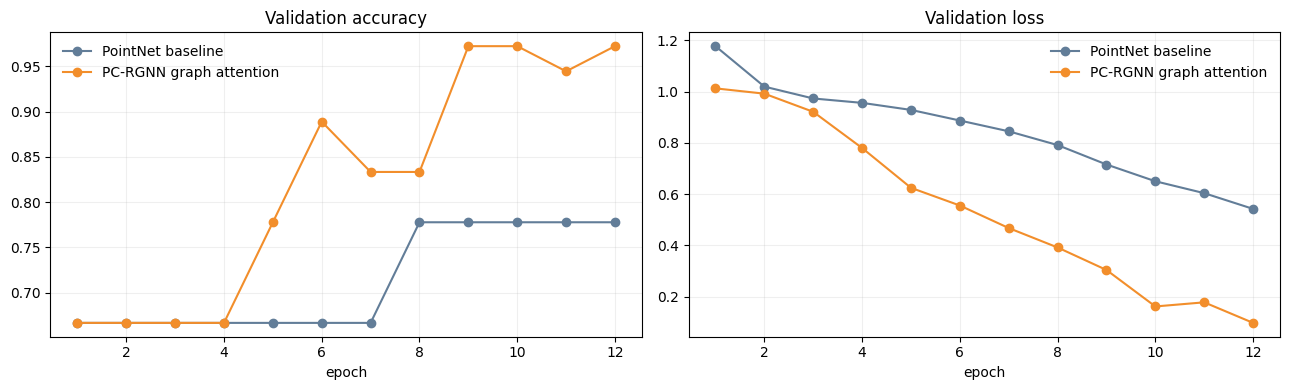

              precision    recall  f1-score   support

       bunny       0.96      1.00      0.98        24
       curve       1.00      1.00      1.00         4
    lamppost       1.00      1.00      1.00         4
       plane       1.00      0.75      0.86         4

    accuracy                           0.97        36
   macro avg       0.99      0.94      0.96        36
weighted avg       0.97      0.97      0.97        36



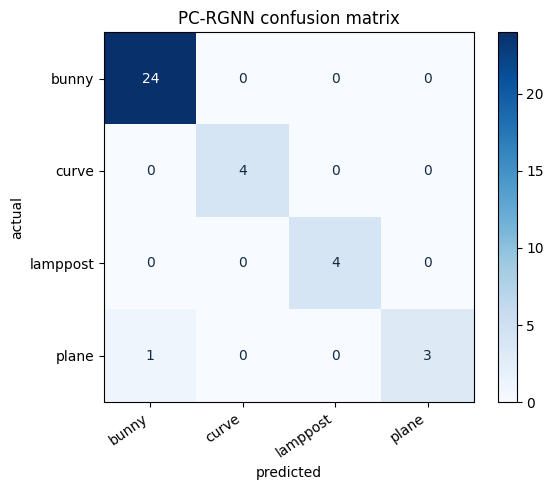

In [8]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
for history,label,color in [(baseline_history,'PointNet baseline','#627d98'),(graph_history,'PC-RGNN graph attention','#f28e2b')]:
    axes[0].plot(history.epoch, history.val_acc, marker='o', label=label, color=color); axes[1].plot(history.epoch, history.val_loss, marker='o', label=label, color=color)
axes[0].set_title('Validation accuracy'); axes[1].set_title('Validation loss')
for ax in axes: ax.set_xlabel('epoch'); ax.grid(alpha=.2); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

def predict(model, loader):
    model.eval(); predicted=[]; actual=[]
    with torch.no_grad():
        for points,target in loader: predicted.extend(model(points.to(DEVICE)).argmax(1).cpu().numpy()); actual.extend(target.numpy())
    return np.array(actual),np.array(predicted)

y_true,y_pred=predict(graph_model,val_loader); print(classification_report(y_true,y_pred,target_names=class_names,zero_division=0))
cm=confusion_matrix(y_true,y_pred,labels=np.arange(len(class_names))); fig,ax=plt.subplots(figsize=(6,5)); im=ax.imshow(cm,cmap='Blues'); ax.set_xticks(range(len(class_names)),class_names,rotation=35,ha='right'); ax.set_yticks(range(len(class_names)),class_names); ax.set_xlabel('predicted'); ax.set_ylabel('actual'); ax.set_title('PC-RGNN confusion matrix')
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]): ax.text(j,i,cm[i,j],ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else '#102a43')
plt.colorbar(im,ax=ax,fraction=.046); plt.tight_layout(); plt.show()

## 4. Inspect learned attention

The model exposes local, context, and global pooling attention. The next view highlights which nodes receive the most global pooling weight for one validation example.

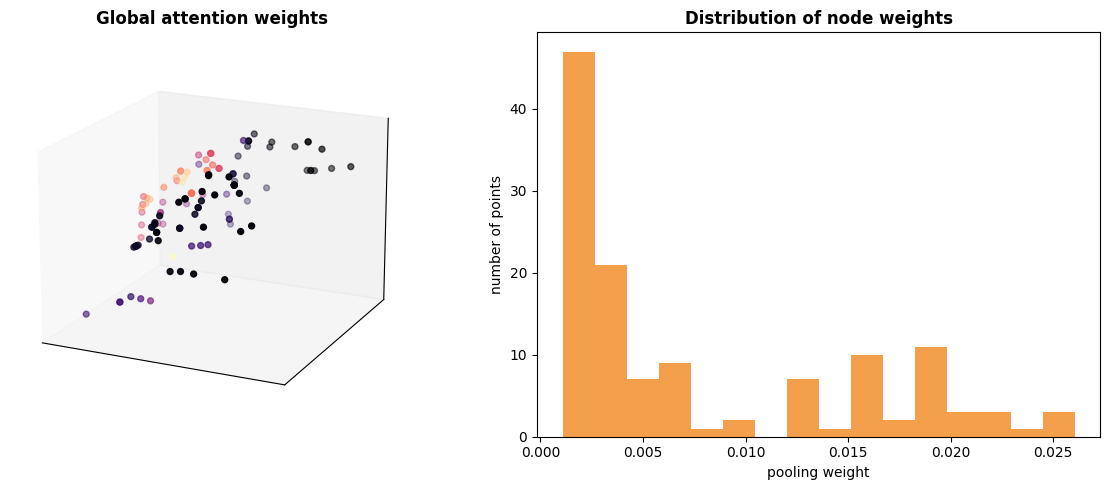

predicted: bunny


In [9]:
graph_model.eval(); example_points=torch.from_numpy(X[val_idx[0]]).unsqueeze(0).to(DEVICE)
with torch.no_grad(): logits,aux=graph_model(example_points,return_aux=True)
attention=aux['pool_weights'][0].cpu().numpy(); points=example_points[0].cpu().numpy()
fig=plt.figure(figsize=(12,5)); ax=fig.add_subplot(1,2,1,projection='3d'); ax.scatter(points[:,0],points[:,1],points[:,2],c=attention,cmap='magma',s=18); ax.set_title('Global attention weights',fontweight='bold'); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=18,azim=-65)
ax2=fig.add_subplot(1,2,2); ax2.hist(attention,bins=16,color='#f28e2b',alpha=.85); ax2.set_title('Distribution of node weights',fontweight='bold'); ax2.set_xlabel('pooling weight'); ax2.set_ylabel('number of points'); plt.tight_layout(); plt.show()
print('predicted:',class_names[int(logits.argmax(1).item())])

## 5. Visualization dashboard

These views make the data and model behavior easier to inspect: class balance, graph connectivity, local attention, and the learned embedding space.

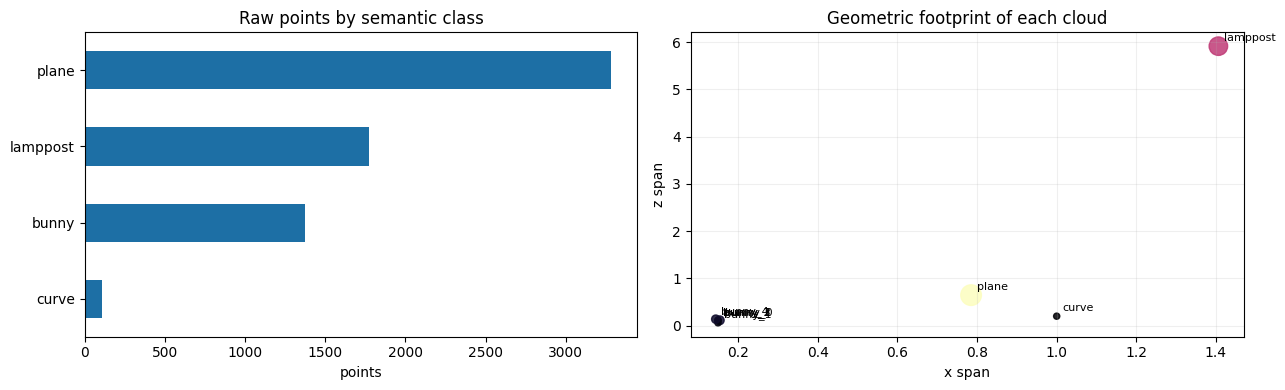

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
summary.groupby('class')['points'].sum().sort_values().plot(kind='barh', ax=axes[0], color='#1d6fa5', title='Raw points by semantic class')
axes[0].set_xlabel('points'); axes[0].set_ylabel('')
axes[1].scatter(summary['x_span'], summary['z_span'], s=np.clip(summary['points'] / 10, 20, 220), c=summary['points'], cmap='magma', alpha=.85)
for _, row in summary.iterrows(): axes[1].annotate(row['cloud'], (row['x_span'], row['z_span']), xytext=(4, 4), textcoords='offset points', fontsize=8)
axes[1].set_title('Geometric footprint of each cloud'); axes[1].set_xlabel('x span'); axes[1].set_ylabel('z span'); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()

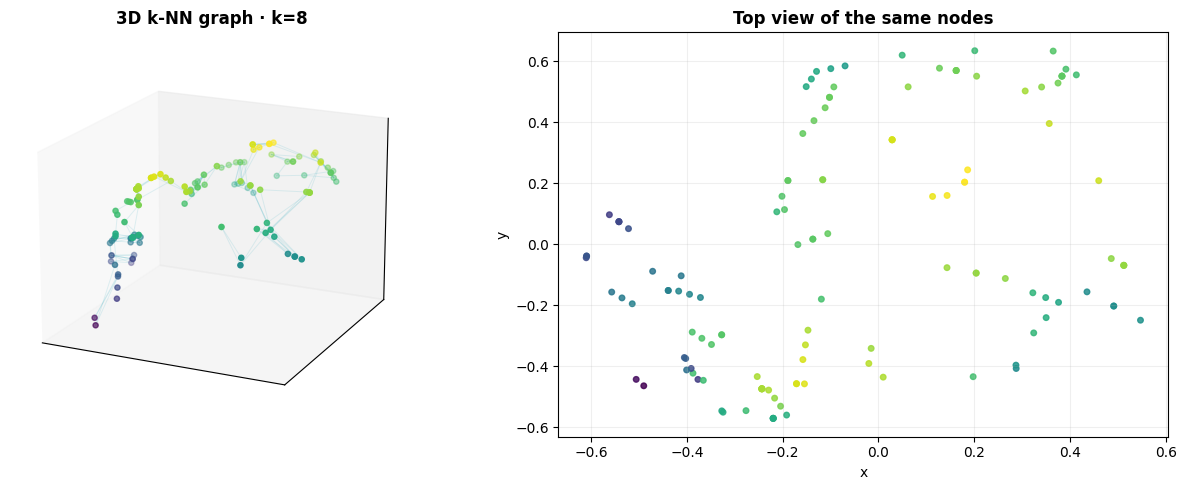

In [11]:
def draw_knn_graph(points, k=8, max_edges=180, seed=SEED):
    tree = cKDTree(points); _, neighbours = tree.query(points, k=k+1); edges=[]
    for i in range(len(points)):
        for j in neighbours[i, 1:]:
            if i < j: edges.append((i, j))
    rng = np.random.default_rng(seed); edges = [edges[i] for i in rng.choice(len(edges), min(max_edges, len(edges)), replace=False)]
    fig = plt.figure(figsize=(13, 5)); ax = fig.add_subplot(1, 2, 1, projection='3d'); ax2 = fig.add_subplot(1, 2, 2)
    for i, j in edges:
        ax.plot([points[i,0], points[j,0]], [points[i,1], points[j,1]], [points[i,2], points[j,2]], color='#4cb6c7', alpha=.16, linewidth=.7)
    ax.scatter(points[:,0], points[:,1], points[:,2], c=points[:,2], cmap='viridis', s=14); ax.set_title(f'3D k-NN graph · k={k}', fontweight='bold'); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.view_init(elev=18, azim=-65)
    ax2.scatter(points[:,0], points[:,1], c=points[:,2], cmap='viridis', s=16, alpha=.85); ax2.set_title('Top view of the same nodes', fontweight='bold'); ax2.set_xlabel('x'); ax2.set_ylabel('y'); ax2.grid(alpha=.2)
    plt.tight_layout(); plt.show()

draw_knn_graph(X[0], k=8)

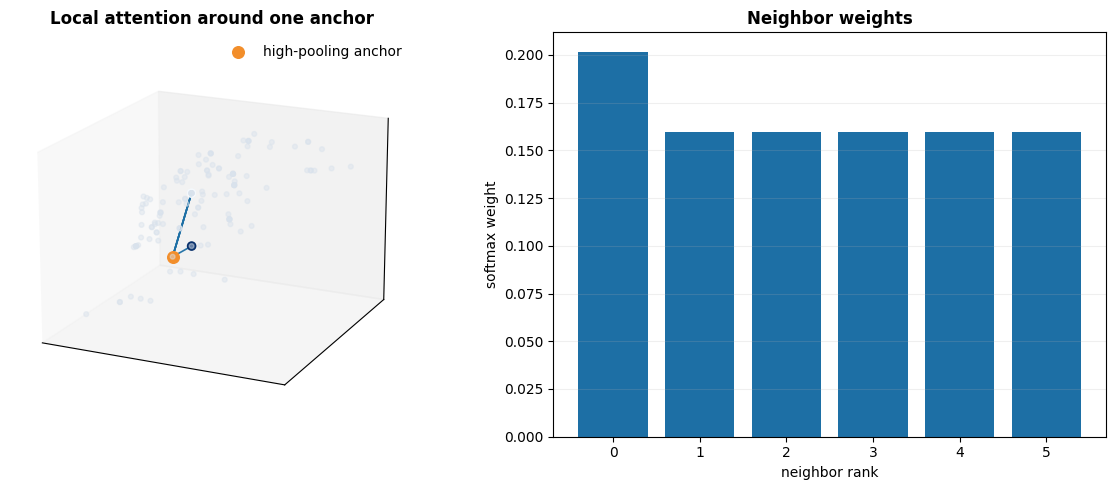

In [12]:
graph_model.eval(); sample = torch.from_numpy(X[val_idx[0]]).unsqueeze(0).to(DEVICE)
with torch.no_grad(): logits, aux = graph_model(sample, return_aux=True)
points = sample[0].cpu().numpy(); anchor = int(aux['pool_weights'][0].argmax().item()); neighbours = aux['local_idx'][0, anchor].cpu().numpy(); weights = aux['local_weights'][0, anchor].cpu().numpy()
fig = plt.figure(figsize=(12, 5)); ax = fig.add_subplot(1, 2, 1, projection='3d'); ax.scatter(points[:,0], points[:,1], points[:,2], color='#d9e2ec', s=12, alpha=.45)
ax.scatter(points[anchor,0], points[anchor,1], points[anchor,2], color='#f28e2b', s=70, label='high-pooling anchor')
for j, w in zip(neighbours, weights): ax.plot([points[anchor,0], points[j,0]], [points[anchor,1], points[j,1]], [points[anchor,2], points[j,2]], color='#1d6fa5', alpha=.25 + .7 * float(w / weights.max()), linewidth=1.2)
ax.scatter(points[neighbours,0], points[neighbours,1], points[neighbours,2], c=weights, cmap='Blues', s=35); ax.set_title('Local attention around one anchor', fontweight='bold'); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.legend(frameon=False); ax.view_init(elev=18, azim=-65)
ax2 = fig.add_subplot(1, 2, 2); order = np.argsort(weights)[::-1]; ax2.bar(np.arange(len(weights)), weights[order], color='#1d6fa5'); ax2.set_title('Neighbor weights', fontweight='bold'); ax2.set_xlabel('neighbor rank'); ax2.set_ylabel('softmax weight'); ax2.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.show()

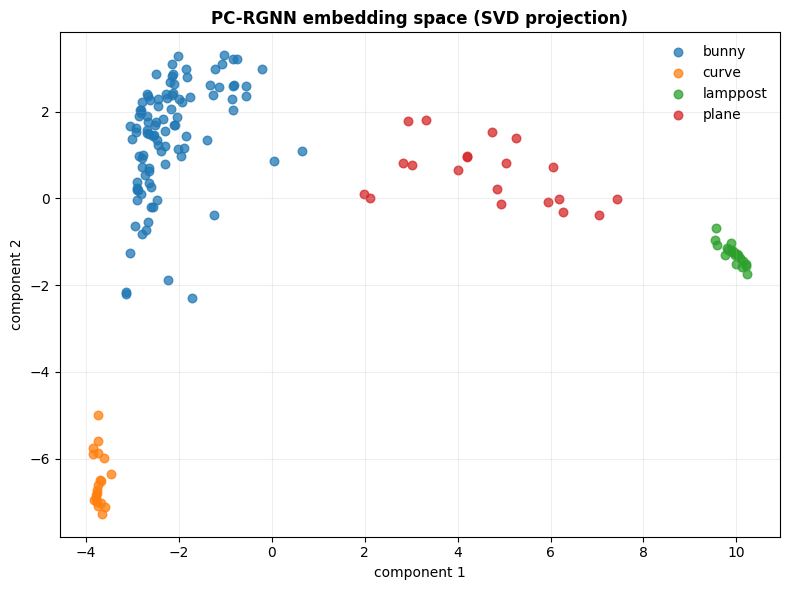

In [13]:
embedding = []
with torch.no_grad():
    for start in range(0, len(X), 16):
        _, aux = graph_model(torch.from_numpy(X[start:start+16]).to(DEVICE), return_aux=True)
        embedding.append(aux['pooled'].cpu().numpy())
embedding = np.vstack(embedding); centered = embedding - embedding.mean(axis=0, keepdims=True); _, _, vh = np.linalg.svd(centered, full_matrices=False); projection = centered @ vh[:2].T
fig, ax = plt.subplots(figsize=(8, 6))
for class_id, label in enumerate(class_names):
    mask = y == class_id; ax.scatter(projection[mask,0], projection[mask,1], s=38, alpha=.75, label=label)
ax.set_title('PC-RGNN embedding space (SVD projection)', fontweight='bold'); ax.set_xlabel('component 1'); ax.set_ylabel('component 2'); ax.grid(alpha=.2); ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 6. Interpretation and next steps

This notebook demonstrates the complete modeling loop rather than a production detector. To turn it into a publishable PC-RGNN experiment, replace the compact PCL corpus with a proper split from KITTI or nuScenes, add 3D box annotations, and train a completion head against ground-truth geometry.

Limitations: the corpus is small and imbalanced; augmentation-based validation can overestimate generalization because some classes have only one source cloud; completion is geometry-aware interpolation rather than a learned GAN; classification is used as a tractable notebook objective, while 3D box regression needs labeled detection data.